## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.



In [ ]:
# @title Ingrese datos
nombre_estudiante = "Simon Mateo Barrios" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**


Una empresa debe de administrar sus tareas tecnicas de acuerdo con su nivel de prioridad y conectar 6 dispositivos utilizando la menor cantidad de cable posible. Para administrar las tareas se implementara una cola de prioridad mediante un Max-Heap, permitiendo procesar primero las tareas mas importantes. Para conectar los dispositivos se utilizará el algoritmo de Kruskal, construyendo un árbol de expansión mínima
que conecte todos los dispositivos sin generar ciclos.

## 2) Requerimientos **[2 pts]**

Lista requerimientos **funcionales** y **no funcionales**.

RQF001//Almacenar las tareas con codigo, descripcion y prioridad
RQF002//Construir un Max-Heap
RQF003//Mostrar el arreglo inicial y el arbol resultante
RQF004//Extraer las dos tareas de mayor prioridad
RQF005//Insertar una nueva tarea con prioridad 12

RQNF001//Utilizar el lenguaje de pyhton
RQNF002//No utilizar libreria heapq
RQNF003//No utilizar funciones que calculen automaticamente el MST
RQNF004//Presentar resultados claros y ordenados
RQNF005//Desarrollar la solucion en un unico Notebook

## 3) Historias de usuario **[2 pts]**
Escribe 3–5 historias de usuario con el formato visto en clase:
Incluye criterios de aceptación.


HSTDU001//Como administrador, quiero organizar las tareas por prioridad para atender primero las mas importantes
HSTDU002//Como tecnico, quiero extraer las tareas de mayor prioridad para atender las situaciones mas urgentes
HSTDU003//Como administrador, quiero insertar muevas tareas urgentes para actualizar el orden de atencion
HSTDU004//Como ingeniero quiero calcular las distancias entre los dispositivos para conocer los costos de conexion
HSTDU005//Como ingeniero quiero conectar todos los dispositivos utilizando la menor cantidad de cable posible

## 4) Diagramas de flujo **[5 pts]**
Incluye el diagrama que muestre el proceso general

Adjunta imagen y descríbelo claramente.
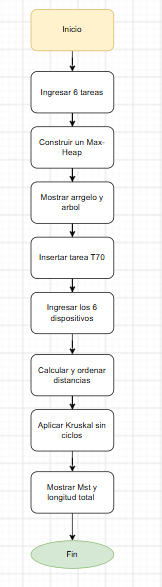
El programa inicia ingresando las 6 tareas y construyendo el Max-Heap. Posteriormen5te exstraer las dos tareas de mayor prioridad  e inserta una nueva tarea
Luego se ingresan los dispositivos se calculan las distancias y se aplica el algoritmo de Kurskal para seleccionar las conexiones de menor costo sin generar ciclos
Finalmente se muestra el arbol de expansion minima y la longityd total del cable utilizado.

### 5) Análisis de complejidad **[15 pts]**
Incluye:
- Justificación
- Función T[n]
- Mejor y peor caso con gráfica
Se define n como la cantidad de elementos del Heap, y como la cantidad de vertices y E como la cantidad de aristas del grafo
Mejor caso: O(1) cuando el elemento ya cumple la prioridad del Max-Heap
Peor caso: O(log  n) cuando el elemento debe descender hasta el ultimo nivel del arbol
T(n) = T(n/2) + c como modelo simplificado de descenso por niveles
El algoritmo ordena las aristas por peso y selecciona las conexiones que no generan ciclos
Ordenamiento: O(E log E) el peor caso.
La implementacion basica de FIND puede recorrer hasta V de elementos
Peor caso de la implementacion:
O(E log E + E*V)
Con la lista de aristas ya ordenado y busquedas de costo constante, el mejor caso puede ser O(E)
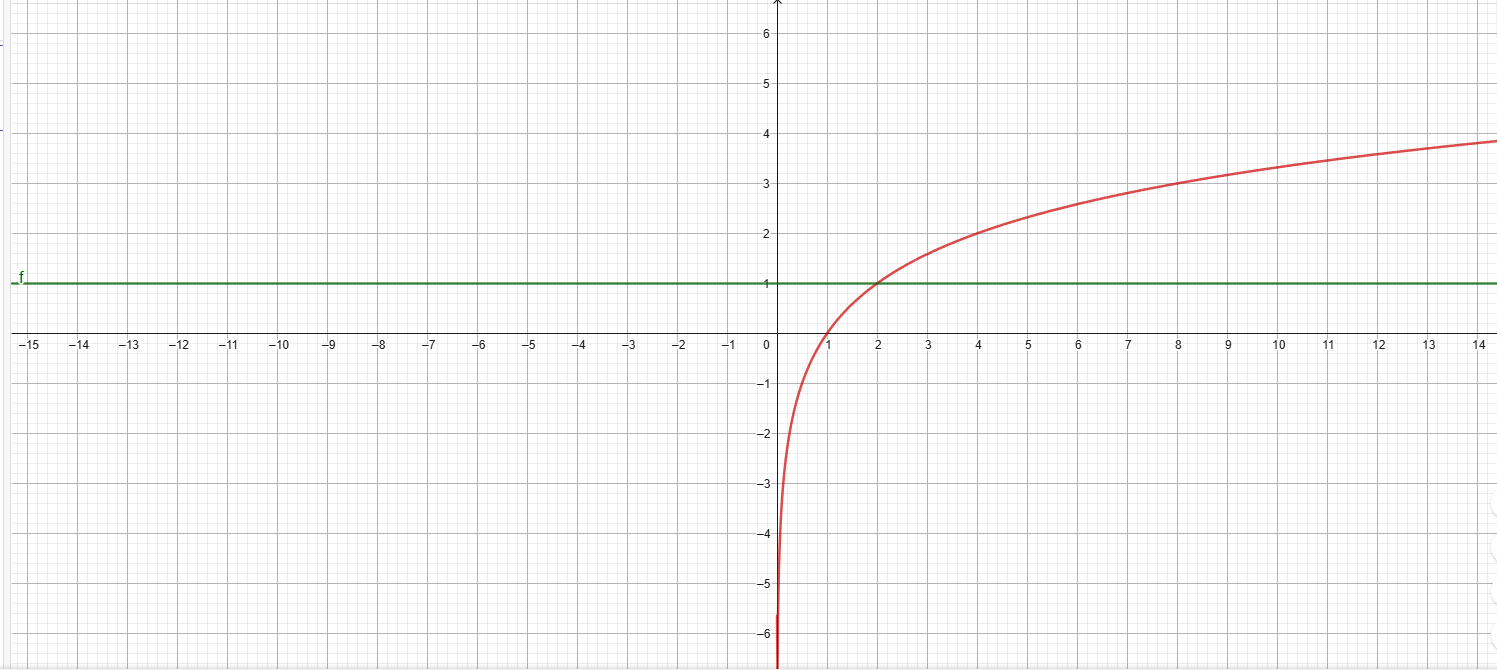


## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [4]:
import math
import matplotlib.pyplot as plt

# PUNTO 1

tareas = [
["T01", "Configurar servidor", 6],
["T02", "Reparar sensor", 10],
["T03", "Actualizar software", 4],
["T04", "Revisar camara", 8],
["T05", "Generar respaldo", 3],
["T06", "Configurar alarma", 7]
]

def max_heapify(A, i):
pos = i
izq = 2*i + 1
der = 2*i + 2

if izq < len(A):
if A[izq][2] > A[pos][2]:
pos = izq

if der < len(A):
if A[der][2] > A[pos][2]:
pos = der

if pos != i:
aux = A[i]
A[i] = A[pos]
A[pos] = aux
max_heapify(A, pos)

def build_max_heap(A):
for i in range(len(A)//2-1, -1, -1):
max_heapify(A, i)

print("PUNTO 1")
print("Arreglo inicial:")
print(tareas)

build_max_heap(tareas)

print("Max-Heap:")
print(tareas)

print("Arbol de prioridades:")
print(" ", tareas[0][2])
print(" ", tareas[1][2], " ", tareas[2][2])
print(" ", tareas[3][2], tareas[4][2], " ", tareas[5][2])

# Grafica del Heap

plt.figure()

posiciones = [
(4, 3),
(2, 2),
(6, 2),
(1, 1),
(3, 1),
(5, 1)
]

for i in range(len(tareas)):
x, y = posiciones[i]

if i > 0:
padre = (i-1)//2
xp, yp = posiciones[padre]
plt.plot([xp, x], [yp, y], color="black")

plt.scatter(x, y, s=900, color="lightblue")
plt.text(x, y, str(tareas[i][2]), ha="center", va="center")

plt.title("Max-Heap")
plt.axis("off")
plt.show()


# PUNTO 2

def extract_max(A):
if len(A) == 0:
return None

tarea = A[0]
A[0] = A[-1]
A.pop()

if len(A) > 0:
max_heapify(A, 0)

return tarea

print("PUNTO 2")

procesada1 = extract_max(tareas)

print("Primera tarea procesada:")
print(procesada1)
print("Heap:", tareas)

procesada2 = extract_max(tareas)

print("Segunda tarea procesada:")
print(procesada2)
print("Heap:", tareas)

nueva = ["T07", "Falla en sistema contra incendios", 12]

tareas.append(nueva)

build_max_heap(tareas)

print("Heap despues de insertar:")
print(tareas)


# PUNTO 3

print("PUNTO 3")

dispositivos = {
"A": (2, 2),
"B": (7, 3),
"C": (4, 7),
"D": (10, 8),
"E": (13, 3),
"F": (15, 7)
}

plt.figure()

for nodo in dispositivos:
x, y = dispositivos[nodo]
plt.scatter(x, y, color="blue")
plt.text(x, y+0.3, nodo)

plt.title("Dispositivos")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid()
plt.axis("equal")
plt.show()

nodos = list(dispositivos)
aristas = []

print("Distancias entre dispositivos:")

for i in range(len(nodos)):
for j in range(i+1, len(nodos)):
a = nodos[i]
b = nodos[j]

x1, y1 = dispositivos[a]
x2, y2 = dispositivos[b]

d = math.sqrt((x2-x1)**2 + (y2-y1)**2)

aristas.append([a, b, d])

print(a, "-", b, ":", round(d, 2))

print("Cantidad de aristas:", len(aristas))


# PUNTO 4

print("PUNTO 4")

def peso(arista):
return arista[2]

aristas.sort(key=peso)

print("Aristas ordenadas:")

for a, b, d in aristas:
print(a, "-", b, ":", round(d, 2))

grupos = {}

for nodo in nodos:
grupos[nodo] = nodo

mst = []
total = 0

for a, b, d in aristas:

if grupos[a] != grupos[b]:

mst.append([a, b, d])

total = total + d

anterior = grupos[b]
nuevo = grupos[a]

for nodo in nodos:
if grupos[nodo] == anterior:
grupos[nodo] = nuevo

if len(mst) == 5:
break

print("Conexiones seleccionadas:")

for a, b, d in mst:
print(a, "-", b, ":", round(d, 2))

print("Longitud total:", round(total, 2))
print("Cantidad de conexiones:", len(mst))


# PUNTO 5

print("PUNTO 5")

plt.figure(figsize=(8, 5))

for nodo in dispositivos:
x, y = dispositivos[nodo]
plt.scatter(x, y, color="blue")
plt.text(x, y+0.3, nodo)

for a, b, d in mst:

x1, y1 = dispositivos[a]
x2, y2 = dispositivos[b]

plt.plot([x1, x2], [y1, y2], color="green")

x = (x1+x2)/2
y = (y1+y2)/2

plt.text(x, y, str(round(d, 2)))

plt.title("MST - Cable total: " + str(round(total, 2)))
plt.xlabel("X")
plt.ylabel("Y")
plt.grid()
plt.axis("equal")
plt.show()


# TESTS APLICADOS

print("TESTS")

assert procesada1[2] == 10
print("Test 1 correcto")

assert procesada2[2] == 8
print("Test 2 correcto")

assert tareas[0][2] == 12
print("Test 3 correcto")

assert len(tareas) == 5
print("Test 4 correcto")

for i in range(1, len(tareas)):
padre = (i-1)//2
assert tareas[padre][2] >= tareas[i][2]

print("Test 5 correcto")

assert len(aristas) == 15
print("Test 6 correcto")

assert len(mst) == 5
print("Test 7 correcto")

assert round(total, 2) == 25.50
print("Test 8 correcto")

assert len(set(grupos.values())) == 1
print("Test 9 correcto")

assert extract_max([]) is None
print("Test 10 correcto")

print("TODAS LAS PRUEBAS CORRECTAS")

IndentationError: expected an indented block after function definition on line 15 (2709436866.py, line 16)

## 7) Tests aplicados **[15 pts]**

In [ ]:
# (Opcional) Ejemplo de asserts (ajusta a tu código):
# assert funcion(0) == 0
# assert funcion(1) == 1
# assert funcion(6) == 8
